# O impacto das escolhas individuais em algoritmos que afetam a todos 

Nesse notebook, vamos usar apenas um dataset (os microdados do ENEM de 2023) e montar 
dois algoritmos simples:

1. **Um ranking**: existe um número limitado de vagas e precisamos decidir quem entra.
2. **Um classificador**: um programa de bolsa que tenta predizer se um(a) estudante terá uma boa nota no ENEM.

Em nenhum momento vamos mudar os dados. Vamos apenas brincar com as *escolhas* que são feitas 
quando construímos algoritmos. O que vale mais, quais features devem ser usadas, como definimos a
"resposta correta" etc. Como é de se imaginar, cada escolha move o resultado em uma direção 
diferente. 

O nosso objetivo aqui não é achar uma resposta certa. Não existe resposta certa. O ponto é
mostrar que **não existe escolha neutra**.  

## 0. Aquisição de dados

### 0.1 Rodar local

1. Na página dos microdados do INEP: https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/microdados/enem
2. Baixe **ENEM 2023** (`microdados_enem_2023.zip`, aprox 600 MB).
3. O arquivo que precisamos é `DADOS/MICRODADOS_ENEM_2023.csv` (about 1.6 GB).

O arquivo `DICIONÁRIO/Dicionário_Microdados_Enem_2023.xlsx`) é um dicionário de dados e explica todos os códigos usados durante o nosso notebook. 

**Obs.**: Estamos pegando os dados de 2023 porque a partir de 2024, o INEP publicou as notas e as informações
dos participantes em arquivos diferentes sem colunas que nos permitam relacionar as coisas. Pra 
esse componente prático, precisamos de tudo numa mesma linha.)

In [1]:
# Mude pro caminho onde vc salvou seus dados
ARQUIVO_DADOS = "microdados_enem_2023/DADOS/MICRODADOS_ENEM_2023.csv"

# O arquivo tem 3.9 milhões de linhas. 50.000 é suficiente pra gente ver o 
# impacto das decisões e mantém o notebook rápido.
TAMANHO_AMOSTRA = 50000

# Seed de gerador aleatório
RANDOM_SEED = 42

### 0.2 Rodar no Colab

<--- instruções p colab --->

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

## 1. Carregando dados

Pra otimizar nosso código, não vamos carregar todas as colunas, 
apenas as necessárioas

| Coluna | Descrição |
|---|---|
| `TP_SEXO` | Sexo (Feminino / Masculino) |
| `TP_COR_RACA` | Raça/cor (auto-declarado) |
| `TP_ESCOLA` | Escola pública / privada) |
| `IN_TREINEIRO` | 1 = treineiro |
| `Q006` | Renda mensal (A = sem renda ... Q = a maior) |
| `Q002` | Nível de escolaridade da mãe (A = nunca estudou ... G = ensino superior, H = não sabe) |
| `TP_PRESENCA_*` | Se o estudante apareceu ou não |
| `NU_NOTA_*` | Notas: CN = ciências naturais, CH = humanidades, LC = linguagens, MT = matemática, REDACAO = ...redação |

In [3]:
colunas_selecionadas = [
    "TP_SEXO",
    "TP_COR_RACA",
    "TP_ESCOLA",
    "IN_TREINEIRO",
    "Q006",
    "Q002",
    "TP_PRESENCA_CN",
    "TP_PRESENCA_CH",
    "TP_PRESENCA_LC",
    "TP_PRESENCA_MT",
    "NU_NOTA_CN",
    "NU_NOTA_CH",
    "NU_NOTA_LC",
    "NU_NOTA_MT",
    "NU_NOTA_REDACAO",
]

# Arquivos do INEP usam ";" como separador e "latin-1" como encoding
dados_brutos = pd.read_csv(ARQUIVO_DADOS, sep=";", encoding="latin-1", usecols=colunas_selecionadas)

print("Número de linhas no arquivo principal:", len(dados_brutos))
dados_brutos.head()

Número de linhas no arquivo principal: 3933955


,TP_SEXO,TP_COR_RACA,TP_ESCOLA,IN_TREINEIRO,TP_PRESENCA_CN,TP_PRESENCA_CH,TP_PRESENCA_LC,TP_PRESENCA_MT,NU_NOTA_CN,NU_NOTA_CH,NU_NOTA_LC,NU_NOTA_MT,NU_NOTA_REDACAO,Q002,Q006
0,M,1,1,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,F,F
1,M,1,1,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,E,H
2,F,1,1,0,1,1,1,1,502.0,498.9,475.6,363.2,700.0,E,C
3,F,3,2,0,1,1,1,1,459.0,508.5,507.2,466.7,880.0,D,C
4,F,3,2,0,1,1,1,1,402.5,379.2,446.9,338.3,560.0,B,B


Mantemos apenas os estudantes que fazem sentido pra nossa exploração aqui. OU seja, os estudantes:
* estavam presentes em todas as provas (presença == 1),
* não são treineiros,
* nos informaram se vieram de escola pública ou particular,
* declaram raça/cor.

In [4]:
data = dados_brutos.copy()

# Presentes em todas as provas
data = data[data["TP_PRESENCA_CN"] == 1]
data = data[data["TP_PRESENCA_CH"] == 1]
data = data[data["TP_PRESENCA_LC"] == 1]
data = data[data["TP_PRESENCA_MT"] == 1]
print(f"Antes e depois do filtro de presença: {len(dados_brutos)}, {len(data)}")

# Não são treineiros
data = data[data["IN_TREINEIRO"] == 0]
print(f"Antes e depois do filtro de treineiro: {len(dados_brutos)}, {len(data)}")

# Escola pública ou particular
data = data[(data["TP_ESCOLA"] == 2) | (data["TP_ESCOLA"] == 3)]
print(f"Antes e depois do filtro de escola: {len(dados_brutos)}, {len(data)}")

# Declarou raça/cor: 1 branco, 2 preto, 3 pardo, 4 amarelo, 5 indígena
data = data[data["TP_COR_RACA"].isin([1, 2, 3, 4, 5])]
print(f"Antes e depois do filtro de raça/cor: {len(dados_brutos)}, {len(data)}")

# Remove linhas faltando nota
data = data.dropna(subset=["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO"])
print("Antes e depois de remover linhas com campos faltantes:", len(data))

# Amostragem aleatória pra rodar mais rápido
if len(data) > TAMANHO_AMOSTRA:
    data = data.sample(n=TAMANHO_AMOSTRA, random_state=RANDOM_SEED)

data = data.reset_index(drop=True)
print(f"Tamanho da nossa amostra: {len(data)}")

Antes e depois do filtro de presença: 3933955, 2678264
Antes e depois do filtro de treineiro: 3933955, 2166843
Antes e depois do filtro de escola: 3933955, 1050858
Antes e depois do filtro de raça/cor: 3933955, 1039069
Antes e depois de remover linhas com campos faltantes: 1039069
Tamanho da nossa amostra: 50000


### Criando colunas mais simples de ler

Vamos criar colunas booleanas (sim/não, 1/0) pros grupos que queremos prestar mais atenção:
* `escola_publica`: 1 se o estudante é de escola pública
* `ppi`: 1 se o estudante é preto, pardo ou indígena. Esse é o agrupamento usado pela lei de cotas.
* `mulher`: 1 se `TP_SEXO` é F
* `baixa_renda`: 1 se a faixa de renda da família está na metade mais baixa da nossa amostra de dados.

Vamos transformar as letras de faixa de renda e a educação da mãe em números para usar ambos.
Isso inclusive pode ser questionado, uma vez que essas variáveis podem ou não ser interpretadas como algo que indica ordem.

In [5]:
# Escola
data["escola_publica"] = 0
data.loc[data["TP_ESCOLA"] == 2, "escola_publica"] = 1

# Raça/cor
data["ppi"] = 0
data.loc[data["TP_COR_RACA"] == 2, "ppi"] = 1   # preta 
data.loc[data["TP_COR_RACA"] == 3, "ppi"] = 1   # parda 
data.loc[data["TP_COR_RACA"] == 5, "ppi"] = 1   # indígena

# Sexo
data["mulher"] = 0
data.loc[data["TP_SEXO"] == "F", "mulher"] = 1

# Renda (letra -> número)
renda_alfabeto = "ABCDEFGHIJKLMNOPQ"
renda_numero = {}
for pos, letra in enumerate(renda_alfabeto):
    renda_numero[letra] = pos + 1     # A -> 1, B -> 2, ...
data["renda_nivel"] = data["Q006"].map(renda_numero)

renda_mediana = data["renda_nivel"].median()
data["baixa_renda"] = 0
data.loc[data["renda_nivel"] < renda_mediana, "baixa_renda"] = 1
print(f"Mediana da faixa de renda classe: {renda_mediana} número: {renda_mediana}")

# Escolaridade mãe: letra -> número
# A..G variam de "nunca estudou" pra "nível superior" H = "Não sabe"
# Perguntas:
# 1. em que outras posição deveríamos colocar o H?
# 2. e se a gente removesse o H, quantos dados perderíamos?
# 3. existe uma posição neutra?
# aqui, vamos colocar o H no meio (H = 4). isso é neutro?
escolaridade_mae_numero = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "H": 4}
data["escolaridade_mae"] = data["Q002"].map(escolaridade_mae_numero)

data = data.dropna(subset=["renda_nivel", "escolaridade_mae"]).reset_index(drop=True)

data[["escola_publica", "ppi", "mulher", "baixa_renda", "renda_nivel", "escolaridade_mae"]].head()

Mediana da faixa de renda classe: 3.0 número: 3.0


,escola_publica,ppi,mulher,baixa_renda,renda_nivel,escolaridade_mae
0,1,1,0,0,6,7
1,1,1,1,0,7,7
2,0,0,0,0,4,2
3,1,1,1,0,11,6
4,1,1,1,0,7,7


### Como nossos dados estão distribuído entre grupos?
Antes de começarmos, vamos checar como cada grupo está represetado nos nossos dados. 
Essa vai ser a nossa referência. A partir dela, a gente é capaz de avaliar se algum
grupo está sendo mais ou menos escolhido por nossos algoritmos.

In [6]:
colunas_grupo = ["escola_publica", "ppi", "baixa_renda", "mulher"]

print("Parte de cada grupo na amostra total")
for column in colunas_grupo:
    share = data[column].mean() * 100
    print(f"  {column:15s} {share:5.1f}%")

Parte de cada grupo na amostra total
  escola_publica   79.2%
  ppi              53.0%
  baixa_renda      34.8%
  mulher           58.9%


In [7]:
# Nota média em cada prova por escola
colunas_notas = ["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO"]

data.groupby("escola_publica")[colunas_notas].mean().round(1)

,NU_NOTA_CN,NU_NOTA_CH,NU_NOTA_LC,NU_NOTA_MT,NU_NOTA_REDACAO
escola_publica,,,,,
0,547.9,574.7,559.9,629.5,764.3
1,472.7,503.4,502.4,503.6,593.3


Note que a diferença entre as escolas varia por área. E isso é exatamente o que as regras de ranking
vão explorar.

## Parte A: Ranking. Quem fica com as vagas?

Há um número fixo de vagas na nossa universidade. Cada auno é rankeado por uma pontuação e apenas
os melhores são admitidos.

De novo, nós não vamos tocar nos dados. O que muda é a **regra** que transforma as cinco notas do ENEM
em uma nota final.

In [8]:
# Vamos admitir os melhores 5%
N_VAGAS = int(len(data) * 0.05)
print("Número de vagas:", N_VAGAS)

Número de vagas: 2500


As duas funções auxiliares abaixo vão ser reusadas durante nosso código:

* `admite_melhores_estudantes` ordena os estudantes por uma coluna de pontuação e retorna os primeiros `N_VAGAS`.
* `descreve_dist_grupos` mostra pra gente a distribuição de grupos.

In [9]:
def admite_melhores_estudantes(df, coluna_pontuacao, n_vagas):
    """Ordena estudantes de maior pra menor pontuação e retorna os primeiros n_vagas."""
    alunos_ordenados = df.sort_values(by=coluna_pontuacao, ascending=False)
    admitidos = alunos_ordenados.head(n_vagas)
    return admitidos


def descreve_dist_grupos(selecionado, nome_regra):
    """Retorna um dicionário com a representação de cada grupo (%)."""
    resultado = {"rule": nome_regra}
    for coluna in colunas_grupo:
        resultado[coluna] = round(selecionado[coluna].mean() * 100, 1)
    return resultado

### Regra 1: média simples

Cada área vale o mesmo. Essa parece ser a opção mais neutra. O que você acha? É mesmo?

In [10]:
data["pontuacao_regra_1"] = (
    data["NU_NOTA_CN"]
    + data["NU_NOTA_CH"]
    + data["NU_NOTA_LC"]
    + data["NU_NOTA_MT"]
    + data["NU_NOTA_REDACAO"]
) / 5

admitidos_regra_1 = admite_melhores_estudantes(data, "pontuacao_regra_1", N_VAGAS)
descreve_dist_grupos(admitidos_regra_1, "1. média simples")

{'rule': '1. média simples',
 'escola_publica': np.float64(25.9),
 'ppi': np.float64(23.1),
 'baixa_renda': np.float64(4.0),
 'mulher': np.float64(52.2)}

### Regra 2: mais peso pra matemática (como Ciência da Computação)

Universidades podem escolher **pesos** diferentes pra cada área. Nesse nosso exemplo, a nota
de matemática vale 4x e a de ciências naturais 2x.

In [11]:
peso_cn = 2
peso_ch = 1
peso_lc = 1
peso_mt = 4
peso_redacao = 1
total_peso = peso_cn + peso_ch + peso_lc + peso_mt + peso_redacao

data["pontuacao_regra_2"] = (
    peso_cn * data["NU_NOTA_CN"]
    + peso_ch * data["NU_NOTA_CH"]
    + peso_lc * data["NU_NOTA_LC"]
    + peso_mt * data["NU_NOTA_MT"]
    + peso_redacao * data["NU_NOTA_REDACAO"]
) / total_peso

admitidos_regra_2 = admite_melhores_estudantes(data, "pontuacao_regra_2", N_VAGAS)
descreve_dist_grupos(admitidos_regra_2, "2. mais peso em matemática")

{'rule': '2. mais peso em matemática',
 'escola_publica': np.float64(25.8),
 'ppi': np.float64(22.0),
 'baixa_renda': np.float64(3.4),
 'mulher': np.float64(44.8)}

### Regra 3: mais peso em redação e humanas 

In [12]:
peso_cn = 1
peso_ch = 3
peso_lc = 2
peso_mt = 1
peso_redacao = 3
total_peso = peso_cn + peso_ch + peso_lc + peso_mt + peso_redacao

data["pontuacao_regra_3"] = (
    peso_cn * data["NU_NOTA_CN"]
    + peso_ch * data["NU_NOTA_CH"]
    + peso_lc * data["NU_NOTA_LC"]
    + peso_mt * data["NU_NOTA_MT"]
    + peso_redacao * data["NU_NOTA_REDACAO"]
) / total_peso

admitidos_regra_3 = admite_melhores_estudantes(data, "pontuacao_regra_3", N_VAGAS)
descreve_dist_grupos(admitidos_regra_3, "3. mais peso em humanas")

{'rule': '3. mais peso em humanas',
 'escola_publica': np.float64(26.7),
 'ppi': np.float64(25.1),
 'baixa_renda': np.float64(4.8),
 'mulher': np.float64(57.3)}

### Regra 4: assentos reservados (uma simplificação das cotas)

Em vez de mudar a pontuação, vamos dividir as vagas. Nesse exemplo, deixamos 50% escola pública e 50% pra particular. 
Dentro de cada grupo, calculamos a média simples. Ou seja, se temos 10 vagas, 5 são destinadas aos melhores estudantes da escola pública e 5 aos melhores estudantes geral (pública e particular). 

Brinque com os valores!

**Obs.** A lei de verdade de cotas é mais detalhada e divide cada subgrupo também por renda e raça.

In [13]:
vagas_reservadas = N_VAGAS // 2
vagas_abertas = N_VAGAS - vagas_reservadas

# 1: preenche as vagas dos estudantes de escola pública
estudantes_escola_publica = data[data["escola_publica"] == 1]
admitidos_cotas = admite_melhores_estudantes(estudantes_escola_publica, "pontuacao_regra_1", vagas_reservadas)

# 2: preenchemos as outras vagas com melhores estudantes que ainda não foram admitidos
ainda_nao_admitidos = data.drop(admitidos_cotas.index)
admitidos_geral = admite_melhores_estudantes(ainda_nao_admitidos, "pontuacao_regra_1", vagas_abertas)

admitidos_regra_4 = pd.concat([admitidos_cotas, admitidos_geral])
descreve_dist_grupos(admitidos_regra_4, "4. 50% cotas para escola pública")

{'rule': '4. 50% cotas para escola pública',
 'escola_publica': np.float64(50.0),
 'ppi': np.float64(27.8),
 'baixa_renda': np.float64(7.9),
 'mulher': np.float64(50.4)}

### Comparando

In [14]:
rows = []
rows.append(descreve_dist_grupos(data, "todos (referência)"))
rows.append(descreve_dist_grupos(admitidos_regra_1, "1. média simples"))
rows.append(descreve_dist_grupos(admitidos_regra_2, "2. mais peso em exatas"))
rows.append(descreve_dist_grupos(admitidos_regra_3, "3. mais peso em humanas"))
rows.append(descreve_dist_grupos(admitidos_regra_4, "4. 50% cotas para escola pública"))

ranking_resultados = pd.DataFrame(rows).set_index("rule")
ranking_resultados

,escola_publica,ppi,baixa_renda,mulher
rule,,,,
todos (referência),79.2,53.0,34.8,58.9
1. média simples,25.9,23.1,4.0,52.2
2. mais peso em exatas,25.8,22.0,3.4,44.8
3. mais peso em humanas,26.7,25.1,4.8,57.3
4. 50% cotas para escola pública,50.0,27.8,7.9,50.4


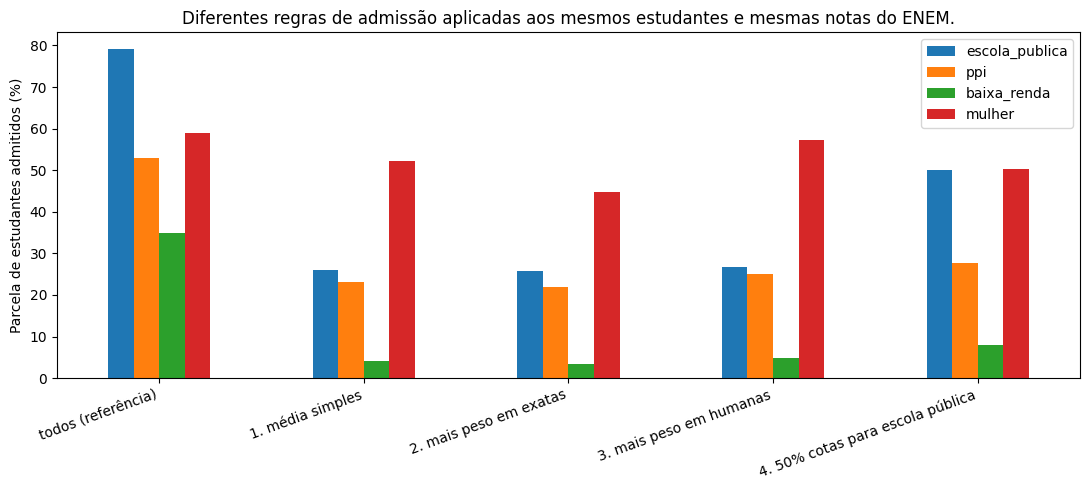

In [15]:
ax = ranking_resultados.plot(kind="bar", figsize=(11, 5))
ax.set_ylabel("Parcela de estudantes admitidos (%)")
ax.set_xlabel("")
ax.set_title("Diferentes regras de admissão aplicadas aos mesmos estudantes e mesmas notas do ENEM.")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Quantos estudantes admitidos na média simples perdem suas vagas quando mudamos a regra? 

In [16]:
admitidos_sets = {
    "2. mais peso em exatas": admitidos_regra_2,
    "3. mais peso em humanas": admitidos_regra_3,
    "4. 50% cota p/ escola pública": admitidos_regra_4,
}

estudantes_regra_1 = set(admitidos_regra_1.index)

for nome_regra, admitidos in admitidos_sets.items():
    estudantes_outra_regra = set(admitidos.index)
    vaga_perdida = estudantes_regra_1 - estudantes_outra_regra
    pct_perdida = len(vaga_perdida) / N_VAGAS * 100
    print(f"{nome_regra:38s} {len(vaga_perdida):5d} estudantes mudam ({pct_perdida:.1f}% das vagas)")

2. mais peso em exatas                   369 estudantes mudam (14.8% das vagas)
3. mais peso em humanas                  304 estudantes mudam (12.2% das vagas)
4. 50% cota p/ escola pública            603 estudantes mudam (24.1% das vagas)


**Questões para refletir**

* A Regra 1 trata todo mundo igual. Isso a torna uma regra neutra? Quem escolheu que todas as notas deveriam ter o mesmo peso pra começo de conversa?
* As Regras 2 e 3 (mais peso pra áreas específicas do conhecimento) não foram pensadas com nenhum grupo específico em mente. Isso faz com que seu resultado também seja igual e neutro? O quanto essas regras mudam a distribuição de quem entra?
* As regras 4 e 5 dizem respeito *explicitamente* a um grupo. As regras 2 e 3 não. Que tipo de escolha é
mais fácil de perceber? Qual delas é mais fácil de discutir em público?

--- 
## Parte B: Classificação. Quem o modelo "encontra"?

Agora vamos trocar um pouco de cenário (mas não muito). Um programa de bolsas de estudo quer identificar alunos promissores
**antes** que façam a prova, usando apenas o questionário socioeconômico. Pra isso, treinam um modelo com os dados do ano passado
para prever quem terá uma **pontuação alta**.

(O que você acha? É uma boa ideia prever o futuro de alguém com base em seu histórico familiar?
Essa escolha de design por si só já é importante. Vamos revisitar daqui a pouco.)

Usaremos uma **regressão logística**, um dos classificadores mais simples. Ela retorna uma probabilidade
entre 0 e 1 para cada aluno, sendo 0 = pontuação baixa e 1 = pontuação alta.

### Etapa 1: definindo a "resposta correta" (o rótulo)

Um modelo precisa de um objetivo. "Pontuador alto" soa objetivo, mas precisamos escolher o que isso significa.

Para a nossa exploração, vamos considerar que uma pontuação alta é uma pontuação maior que os 25% mais altos da média simples.
Ou seja, se a nota do ENEM vai de 0 a 1000, uma pontuação alta é qualquer coisa que na média é maior ou igual 750.

In [17]:
cutoff_media = data["pontuacao_regra_1"].quantile(0.75)

data["alta_pontuacao_media"] = 0
data.loc[data["pontuacao_regra_1"] >= cutoff_media, "alta_pontuacao_media"] = 1

print("Porcentagem de pontuações altas:", round(data["alta_pontuacao_media"].mean() * 100, 1), "%")

Porcentagem de pontuações altas: 25.0 %


### Etapa 2: divisão dos dados em treino e teste

Treinamos o modelo com 70% dos alunos e o avaliamos com os 30% restantes, que nunca foram vistos pelo modelo.

In [18]:
dados_treino, dados_teste = train_test_split(data, test_size=0.3, random_state=RANDOM_SEED)
dados_treino = dados_treino.copy()
dados_teste = dados_teste.copy()

print(f"Dados de treino: {len(dados_treino)}")
print(f"Dados de teste:  {len(dados_teste)}")

Dados de treino: 35000
Dados de teste:  15000


### Etapa 3: como mediremos o modelo, grupo por grupo

Para cada grupo (por exemplo, alunos de escolas públicas), olhamos pra três números:

* **selecionados (%)**: qual a porcentagem do grupo que o modelo seleciona para a bolsa de estudos.

* **encontrados (%)**: entre os alunos do grupo que realmente obtiveram notas altas, qual a porcentagem que o modelo
encontrou. (Esta é a *taxa de verdadeiros positivos* ou *recall*.) Um número baixo significa que alunos talentosos
desse grupo estão sendo perdidos.

* **precisão (%)**: com que frequência o modelo acerta para esse grupo.

In [19]:
def avalia_por_grupo(df_teste, predicao, rotulo, nome_modelo):
    """Compara as predições do modelo com os rótulos reais, separando por grupo."""
    linhas = []
    for coluna in colunas_grupo:
        for v in [1, 0]:
            grupo = df_teste[df_teste[coluna] == v]

            if v == 1:
                nome_grupo = coluna
            else:
                nome_grupo = "not " + coluna

            selecionado = grupo[predicao].mean() * 100

            alta_pontuacao = grupo[grupo[rotulo] == 1]
            if len(alta_pontuacao) > 0:
                encontrados = alta_pontuacao[predicao].mean() * 100
            else:
                encontrados = float("nan")

            acuracia = (grupo[predicao] == grupo[rotulo]).mean() * 100

            linhas.append({
                "modelo": nome_modelo,
                "grupo": nome_grupo,
                "selecionados (%)": round(selecionado, 1),
                "encontrados (%)": round(encontrados, 1),
                "acurácia (%)": round(acuracia, 1),
            })
    return pd.DataFrame(linhas)

A bolsa de estudos tem um orçamento fixo: 25% dos alunos. Portanto, em vez de usar o limite de probabilidade usual de 0.5, selecionamos os 25% dos alunos com a maior probabilidade prevista. Esta ferramenta faz isso:

In [20]:
def seleciona_pct_alta(probabilidades, pct):
    """Retorna 1 para estudantes com probabilidades altas, 0 pro resto."""
    n_selecionados = int(len(probabilidades) * pct)

    # Rank: 1 = probabilidade mais alta.
    # Muitos estudantes têm exatamente a mesma probabilidade.
    # method="first" desempata por ordem do data e nosso dataset já foi randomizado, 
    # então os empates são decididos aleatoriamente. Isso é justo??? 
    ranks = pd.Series(probabilidades).rank(method="first", ascending=False)

    selecionado = []
    for rank in ranks:
        if rank <= n_selecionados:
            selecionado.append(1)
        else:
            selecionado.append(0)
    return selecionado


PCT_BOLSA_DE_ESTUDOS = 0.25

### Controle 1: quais features entram no modelo?

Treinaremos três modelos com **os mesmos dados e os mesmos rótulos**. Apenas as colunas de entrada mudam.

* **Modelo A**: tipo de escola, renda e escolaridade da mãe. A raça *não* é usada. ("Não usamos raça como uma feature explícita, então claro que vamos ser justos", né?)
* **Modelo B**: Modelo A + raça (`ppi`).
* **Modelo C**: apenas renda familiar.

In [21]:
def treina_e_prediz(features, rotulo, predicao):
    """Train a logistic regression and save its selections in dados_teste[prediction_column]."""
    modelo = LogisticRegression(max_iter=1000)
    modelo.fit(dados_treino[features], dados_treino[rotulo])

    # prob. de ter uma boa nota (column 1 = class "1")
    probabilidades = modelo.predict_proba(dados_teste[features])[:, 1]
    dados_teste[predicao] = seleciona_pct_alta(probabilidades, PCT_BOLSA_DE_ESTUDOS)

    # Printa os pesos pra gente ver o que o modeloe stá usando
    # na hora de fazer a predição
    print("Model pesos for", predicao)
    for name, peso in zip(features, modelo.coef_[0]):
        print(f"   {name:18s} {peso:+.3f}")
    print()
    
    return probabilidades


features_A = ["escola_publica", "renda_nivel", "escolaridade_mae"]
features_B = ["escola_publica", "renda_nivel", "escolaridade_mae", "ppi"]
features_C = ["renda_nivel"]

probabilidades_A = treina_e_prediz(features_A, "alta_pontuacao_media", "pred_A")
probabilidades_B = treina_e_prediz(features_B, "alta_pontuacao_media", "pred_B")
probabilidades_C = treina_e_prediz(features_C, "alta_pontuacao_media", "pred_C")

Model pesos for pred_A
   escola_publica     -1.214
   renda_nivel        +0.132
   escolaridade_mae   +0.221

Model pesos for pred_B
   escola_publica     -1.182
   renda_nivel        +0.121
   escolaridade_mae   +0.214
   ppi                -0.373

Model pesos for pred_C
   renda_nivel        +0.242



In [22]:
resultados_A = avalia_por_grupo(dados_teste, "pred_A", "alta_pontuacao_media", "A: sem raça/cor")
resultados_B = avalia_por_grupo(dados_teste, "pred_B", "alta_pontuacao_media", "B: com raça/cor")
resultados_C = avalia_por_grupo(dados_teste, "pred_C", "alta_pontuacao_media", "C: apenas renda")

features_resultados = pd.concat([resultados_A, resultados_B, resultados_C])

# Show one small table per measure: rows = groups, columns = models
features_resultados.pivot(index="grupo", columns="modelo", values="selecionados (%)")

modelo,A: sem raça/cor,B: com raça/cor,C: apenas renda
grupo,,,
baixa_renda,2.2,1.7,0.0
escola_publica,6.0,6.3,14.0
mulher,22.9,22.9,22.0
not baixa_renda,37.1,37.4,38.3
not escola_publica,97.4,96.2,66.9
not mulher,27.9,28.0,29.3
not ppi,37.6,40.3,37.2
ppi,13.8,11.4,14.2


In [23]:
features_resultados.pivot(index="grupo", columns="modelo", values="encontrados (%)")

modelo,A: sem raça/cor,B: com raça/cor,C: apenas renda
grupo,,,
baixa_renda,10.1,7.5,0.0
escola_publica,16.6,16.9,30.0
mulher,57.1,56.6,50.3
not baixa_renda,64.2,64.3,59.7
not escola_publica,99.0,98.1,74.5
not mulher,57.2,57.1,53.9
not ppi,65.9,68.3,60.4
ppi,40.7,35.3,35.8


**Perguntas pra explorar**

* O Modelo A não usa a informação de raça/cor. Qual a proporção de estudantes PPI vs estudantes não PPI? É uma proporção justa? Por que não? (Dica: tente ver como `ppi` se relaciona à `escola_publica` e `renda_nivel`.
* Veja o peso que o modelo B dá pra `ppi`. O que ele aprende? Incluir raça/cor como uma fature ajuda ou prejudica os estudantes aqui?
* O modelo "mais simples" (modelo C) é o mais justo?

In [24]:
# Proxies: o quanto features "neutras" dizem sobre raça/cor?
data.groupby("ppi")[["escola_publica", "renda_nivel", "escolaridade_mae"]].mean().round(2)

,escola_publica,renda_nivel,escolaridade_mae
ppi,,,
0,0.69,6.11,5.08
1,0.89,3.74,4.47


### Controle 2: onde definimos o ponto de corte?

Agora, vamos manter o Modelo A fixo (mesmas probabilidades). Mudaremos apenas *como* transformamos
probabilidades em decisões.
* **Um ponto de corte para todos**: os 25% melhores no geral (como fizemos acima).
* **Um ponto de corte por grupo**: os 25% melhores *dentro* das escolas públicas e os 25% melhores *dentro* das escolas particulares.

In [25]:
dados_teste["prob_A"] = probabilidades_A

dados_teste["pred_A_por_grupo"] = 0
for tipo_escola in [0, 1]:
    grupo_escola = dados_teste["escola_publica"] == tipo_escola
    probs_grupo = dados_teste.loc[grupo_escola, "prob_A"]
    selecao_dentro_do_grupo = seleciona_pct_alta(list(probs_grupo), PCT_BOLSA_DE_ESTUDOS)
    dados_teste.loc[grupo_escola, "pred_A_por_grupo"] = selecao_dentro_do_grupo

resultados_A_por_grupo = avalia_por_grupo(
    dados_teste, "pred_A_por_grupo", "alta_pontuacao_media", "A: corte por tipo de escola"
)

resultado_corte = pd.concat([resultados_A, resultados_A_por_grupo])
resultado_corte.pivot(index="grupo", columns="modelo", values="selecionados (%)")

modelo,A: corte por tipo de escola,A: sem raça/cor
grupo,,
baixa_renda,2.1,2.2
escola_publica,25.0,6.0
mulher,23.1,22.9
not baixa_renda,37.2,37.1
not escola_publica,25.0,97.4
not mulher,27.7,27.9
not ppi,32.9,37.6
ppi,17.9,13.8


In [26]:
resultado_corte.pivot(index="grupo", columns="modelo", values="encontrados (%)")

modelo,A: corte por tipo de escola,A: sem raça/cor
grupo,,
baixa_renda,3.7,10.1
escola_publica,45.0,16.6
mulher,38.3,57.1
not baixa_renda,43.7,64.2
not escola_publica,31.7,99.0
not mulher,38.6,57.2
not ppi,43.0,65.9
ppi,29.9,40.7


In [27]:
resultado_corte.pivot(index="grupo", columns="modelo", values="acurácia (%)")

modelo,A: corte por tipo de escola,A: sem raça/cor
grupo,,
baixa_renda,89.2,90.2
escola_publica,73.4,83.3
mulher,71.3,80.5
not baixa_renda,58.6,72.3
not escola_publica,53.3,60.7
not mulher,66.2,75.9
not ppi,62.2,73.4
ppi,75.5,83.1


**Para explorar e reparar:**

* Mantivemos o mesmo modelo e as mesmas probabilidades, só a regra de corte mudou.
* A acurácia geral do modelo diminui um pouco com os cortes específicos por grupo. Quem eprde com isso e quem ganha? A acurácia é a métrica certa pra uma bolsa de estudos? Estamos falando aqui de dar oportunidades pra alguém estudar.
* (Mais sobre métricas no próximo encontro!)

### Controle 3: o que conta como um "alta pontuação"?

Nossa classificação usou a média simples até agora. Mas poderíamos tê-la definido usando só matemática, ou só redação. 
Ambas são escolhas razoáveis pra programas diferentes (uma bolsa de estudos de exatas versus uma bolsa de escrita).

Então agora vamos fazer algumas novas escolhas:
* primeiro, vamos adicionar o sexo como uma feature do Modelo A (vamos supor, sei lá, que alguém do seu time te convenceu de que isso melhora a performance do modelo)
* segundo, vamos treinar novamente o mesmo modelo pra tentar achar estudantes com potencial de cada pontuação para as nossas novas bolsas (uma de exatas e uma de escrita) 

In [28]:
nota_de_corte_exatas = data["NU_NOTA_MT"].quantile(0.75)
nota_de_corte_redacao = data["NU_NOTA_REDACAO"].quantile(0.75)

for df in [dados_treino, dados_teste]:
    df["alta_pontuacao_exatas"] = 0
    df.loc[df["NU_NOTA_MT"] >= nota_de_corte_exatas, "alta_pontuacao_exatas"] = 1

    df["alta_pontuacao_redacao"] = 0
    df.loc[df["NU_NOTA_REDACAO"] >= nota_de_corte_redacao, "alta_pontuacao_redacao"] = 1

novas_features = ["escola_publica", "renda_nivel", "escolaridade_mae", "mulher"]

treina_e_prediz(novas_features, "alta_pontuacao_exatas", "pred_exatas")
treina_e_prediz(novas_features, "alta_pontuacao_redacao", "pred_redacao")

resultados_exatas = avalia_por_grupo(dados_teste, "pred_exatas", "alta_pontuacao_exatas", "rotulo: exatas")
resultados_redacao = avalia_por_grupo(dados_teste, "pred_redacao", "alta_pontuacao_redacao", "rotulo: redacao")

rotulo_resultados = pd.concat([resultados_exatas, resultados_redacao])
rotulo_resultados.pivot(index="grupo", columns="modelo", values="selecionados (%)")

Model pesos for pred_exatas
   escola_publica     -0.967
   renda_nivel        +0.153
   escolaridade_mae   +0.186
   mulher             -0.627

Model pesos for pred_redacao
   escola_publica     -1.110
   renda_nivel        +0.073
   escolaridade_mae   +0.159
   mulher             +0.681



modelo,rotulo: exatas,rotulo: redacao
grupo,,
baixa_renda,1.1,2.2
escola_publica,7.9,6.0
mulher,18.3,26.9
not baixa_renda,37.8,37.1
not escola_publica,90.0,97.2
not mulher,34.5,22.3
not ppi,37.3,37.3
ppi,14.0,14.0


In [29]:
# Como definimos uma alta pontuação? O critério varia por grupos!
pct_rotulo = []
for coluna in colunas_grupo:
    grupo_df = dados_teste[dados_teste[coluna] == 1]
    pct_rotulo.append({
        "grupo": coluna,
        "alta pontuação (média) %": round(grupo_df["alta_pontuacao_media"].mean() * 100, 1),
        "alta pontuação (exatas) %": round(grupo_df["alta_pontuacao_exatas"].mean() * 100, 1),
        "alta pontuação (redação) %": round(grupo_df["alta_pontuacao_redacao"].mean() * 100, 1),
    })
pd.DataFrame(pct_rotulo).set_index("grupo")

,alta pontuação (média) %,alta pontuação (exatas) %,alta pontuação (redação) %
grupo,,,
escola_publica,16.1,16.7,19.0
ppi,16.5,15.7,20.9
baixa_renda,9.5,9.0,16.0
mulher,24.0,19.7,30.1


**Para notar e pensar**

* Compare o peso que o modelo dá pra feature `mulher` nas duas versões. De novo, temos os mesmos dados, as mesmas features e o mesmo algoritmo. O sinal pode mudar só porque a gente mudou qual a nossa definição de uma pontuação alta.
* Nas duas tables, olhe pra linha `mulher`. O viés pode vir da nossa definição de rótulo antes mesmo do algoritmo ser treinado.

---
## Resumo: temos muitas direções possíveis mesmo pra um único conjunto de dados

Vamos colocar agora a porcentagem de escola púbica, PPI e mulher junto dos estudantes selecionados pra todas
as versões que construímos.

In [30]:
resumo_linhas = []

# Part A: rankings
for nome_regra in ranking_resultados.index:
    if nome_regra == "Todo mundo (referência)":
        continue
    resumo_linhas.append({
        "algoritmo": "Ranking - " + nome_regra,
        "escola_publica (%)": ranking_resultados.loc[nome_regra, "escola_publica"],
        "ppi (%)": ranking_resultados.loc[nome_regra, "ppi"],
        "mulher (%)": ranking_resultados.loc[nome_regra, "mulher"],
    })

# Part B: classifiers (share of selecionado students that belong to each group)
classifier_columns = {
    "pred_A": "Classificador A (sem raça/cor)",
    "pred_B": "Classificador B (com raça/cor)",
    "pred_C": "Classificador C (apenas renda)",
    "pred_A_por_grupo": "Classificador A, corte por tipo de escola",
    "pred_exatas": "Classificador A + sexo, rótulo de exatas",
    "pred_redacao": "Classificador A + sexo, rótulo de humanas",
}
for prediction_column, name in classifier_columns.items():
    estudantes_selecionados = dados_teste[dados_teste[prediction_column] == 1]
    resumo_linhas.append({
        "algoritmo": name,
        "escola_publica (%)": round(estudantes_selecionados["escola_publica"].mean() * 100, 1),
        "ppi (%)": round(estudantes_selecionados["ppi"].mean() * 100, 1),
        "mulher (%)": round(estudantes_selecionados["mulher"].mean() * 100, 1),
    })

resumo = pd.DataFrame(resumo_linhas).set_index("algoritmo")
print("Referência (pct de todos os estudantes):",
      "escola_publica =", round(data["escola_publica"].mean() * 100, 1), "%,",
      "ppi =", round(data["ppi"].mean() * 100, 1), "%,",
      "mulher =", round(data["mulher"].mean() * 100, 1), "%")
resumo

Referência (pct de todos os estudantes): escola_publica = 79.2 %, ppi = 53.0 %, mulher = 58.9 %


,escola_publica (%),ppi (%),mulher (%)
algoritmo,,,
Ranking - todos (referência),79.2,53.0,58.9
Ranking - 1. média simples,25.9,23.1,52.2
Ranking - 2. mais peso em exatas,25.8,22.0,44.8
Ranking - 3. mais peso em humanas,26.7,25.1,57.3
Ranking - 4. 50% cotas para escola pública,50.0,27.8,50.4
Classificador A (sem raça/cor),19.0,29.2,53.7
Classificador B (com raça/cor),19.9,24.0,53.7
Classificador C (apenas renda),44.3,29.9,51.5
"Classificador A, corte por tipo de escola",79.2,37.9,54.0


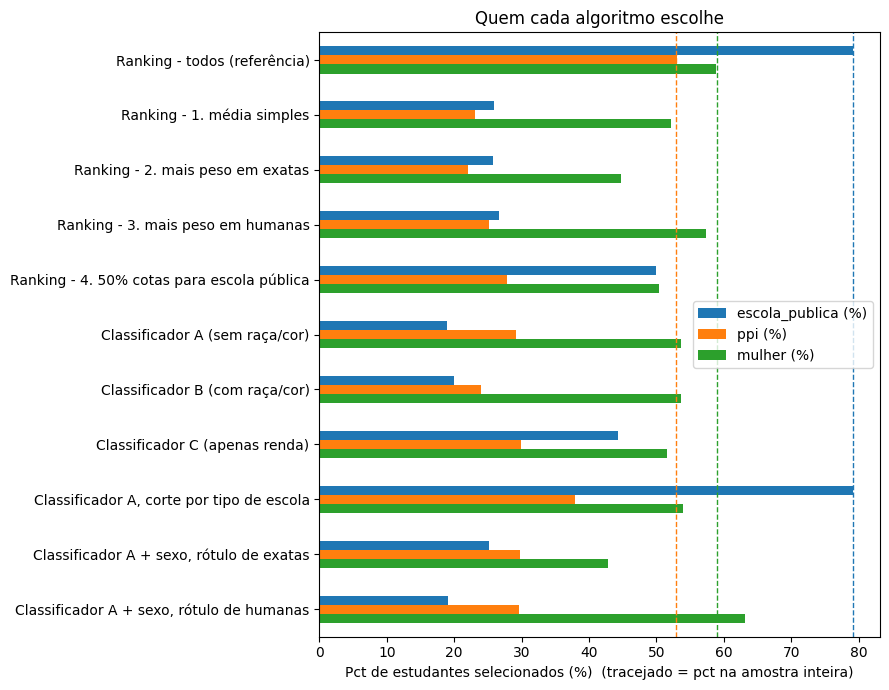

In [31]:
ax = resumo.plot(kind="barh", figsize=(9, 7))
ax.axvline(data["escola_publica"].mean() * 100, linestyle="--", color="tab:blue", linewidth=1)
ax.axvline(data["ppi"].mean() * 100, linestyle="--", color="tab:orange", linewidth=1)
ax.axvline(data["mulher"].mean() * 100, linestyle="--", color="tab:green", linewidth=1)
ax.set_xlabel("Pct de estudantes selecionados (%)  (tracejado = pct na amostra inteira)")
ax.set_ylabel("")
ax.set_title("Quem cada algoritmo escolhe")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## Algumas perguntas
1. Quais escolhas desse notebook parecem técnicas mas têm consequências sociais? (Pesos, features, como escolhemos o 25% etc?)
2. Na parte B, o modelo usado nunca teve acesso às notas dos estudates do conjunto de teste, apenas às suas informações socioeconômicas. O que significa dar uma bolsa de estudos se baseando apenas nisso? 
3. As notas do ENEM já são enviesadas por acesso a educação (ou a cursinhos, por exemplo). Algum algoritmo que é construído em cima dessa base de dados consegue ser "100% justo"? O que isso significaria?
4. Dentre os algoritmos desse notebook, escolha o que você achou mais justo e tente explicar o porquê e qual a sua definição de justiça para essa escolha. Trocaremos figurinhas no próximo encontro. (:  


## Exercícios
* Change `escola_publica_BONUS` and plot how the share of public school students changes.
* Na Parte B, mude os valores dos pesos e dê mais peso pra grupos sub-representados durante o treino 
  (`model.fit(..., sample_peso=...)`). O que muda?
* Repita a anáise pra estudantes de um único estado (`SG_UF_PROVA`). O que se mantém? O que muda?